In [1]:
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 데이터 경로 (Colab이면 드라이브 경로로 변경)
TRAIN_PATH = "train.csv"
PREDICT_PATH = "predict_input.csv"

# 라벨 표기와 색상 통일: 독성 있음 = 빨강, 독성 없음 = 파랑
LABEL_NAME = {0: "독성 있음", 1: "독성 없음"}
LABEL_COLOR = {0: "#d62728", 1: "#1f77b4"}

# 한글 폰트
if platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
elif platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
else:  # Colab: !apt-get -qq install fonts-nanum 후 런타임 재시작
    plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

pd.set_option("display.max_columns", 30)


train = pd.read_csv(TRAIN_PATH)

# 컬럼 그룹
ECFP = [c for c in train.columns if c.startswith("ecfp_")]
FCFP = [c for c in train.columns if c.startswith("fcfp_")]
PTFP = [c for c in train.columns if c.startswith("ptfp_")]
FP = ECFP + FCFP + PTFP
NUM = ["MolWt", "clogp", "sa_score", "qed"]
TARGET = "label"

# (참고) 다변량 분석 조각 – 이변량 분석에서 분리한 부분
물성 **2개 + 독성(label)** 을 동시에 보는 분석이라 이변량이 아니라 **다변량**에 해당합니다. 이변량 노트북(이변량_분석.ipynb)에서 빼서 따로 보관한 내용입니다.

In [2]:
from scipy import stats
import warnings; warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 100
C0, C1 = LABEL_COLOR[0], LABEL_COLOR[1]   # 빨강=독성 있음, 파랑=독성 없음
nm = {'MolWt':'분자량','clogp':'지용성(clogp)','sa_score':'합성 난이도','qed':'약물 유사성(qed)'}
print(train.shape)

(8349, 3078)


## 6. 물성 2개 조합 ↔ 독성
**독성 있음 비율**이 높을수록 칸이 진한 빨강입니다. 두 물성 조합 칸마다 비율을 칠했습니다. 한 물성만 볼 때 놓치는 패턴이 보입니다. (칸당 화합물 15개 미만은 비움)

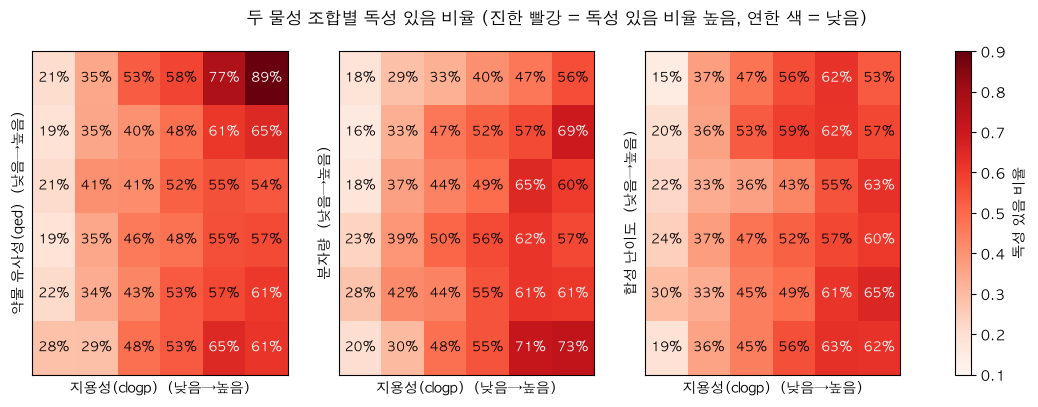

In [3]:
def heat(xc,yc,a):
    d=train.assign(tox=1-train[TARGET],xb=pd.qcut(train[xc],6,labels=False,duplicates='drop'),yb=pd.qcut(train[yc],6,labels=False,duplicates='drop'))
    r=d.pivot_table(index='yb',columns='xb',values='tox',aggfunc='mean')
    n=d.pivot_table(index='yb',columns='xb',values=TARGET,aggfunc='count')
    r=r.where(n>=15)
    im=a.imshow(r.values,origin='lower',cmap='Reds',vmin=.1,vmax=.9,aspect='auto')
    for i in range(r.shape[0]):
        for j in range(r.shape[1]):
            if not np.isnan(r.values[i,j]): a.text(j,i,f'{r.values[i,j]:.0%}',ha='center',va='center',fontsize=9,color='white' if r.values[i,j]>.6 else 'black')
    a.set_xlabel(nm[xc]+'  (낮음→높음)'); a.set_ylabel(nm[yc]+'  (낮음→높음)'); a.set_xticks([]); a.set_yticks([])
    return im
fig,ax=plt.subplots(1,3,figsize=(14,4.2))
for a,(x,y) in zip(ax,[('clogp','qed'),('clogp','MolWt'),('clogp','sa_score')]): im=heat(x,y,a)
fig.colorbar(im,ax=ax,label='독성 있음 비율'); plt.suptitle('두 물성 조합별 독성 있음 비율 (진한 빨강 = 독성 있음 비율 높음, 연한 색 = 낮음)'); plt.show()

#### 그래프 8 · 두 물성 조합별 독성 있음 비율 (진할수록 독성 있음 비율 높음)
- **발견**: 세 그림 모두 **왼쪽(지용성 낮음)은 연한 색, 오른쪽(높음)은 진한 빨강**입니다. 다른 물성을 바꿔도 지용성의 영향이 유지됩니다. 의외로 **지용성 높음 + 약물 유사성 높음** 칸이 가장 진합니다.
- **근거**: 지용성×약물 유사성 그림에서 지용성이 가장 낮은 열은 독성 있음 19~28%인 반면, 가장 높은 열은 대부분 54~65%이고, 약물 유사성이 가장 높은 칸은 **89%**입니다(이 칸은 화합물이 **19개뿐**). 분자량·합성 난이도와 짝지어도 가장 오른쪽 열은 53~73%로 높습니다.
- **이유**: 지용성이 다른 물성과 엮여서 생긴 착시라면 한 물성을 고정했을 때 효과가 사라져야 하는데, 그렇지 않습니다. 89% 칸은 "약 같지만 기름에 매우 잘 녹는 분자" 조합이고, 표본이 적은 칸이라 단정하기는 이릅니다.
- **의미**: 지용성은 다른 물성을 통제해도 독립적인 위험 신호입니다. 두 물성의 **조합(상호작용)** 이 효과를 바꿀 수 있으므로, 이를 잡는 트리 계열 모델이 유리하고, 조합 변수를 만들어 보는 것도 시도해 볼 만합니다.

##### 핵심 분석 ⑤ clogp × qed 조합
**발견**
- 다른 물성을 바꿔도 clogp가 높으면 독성 비율이 높게 유지됨
- clogp가 가장 높은 열에서 qed가 가장 높은 칸이 독성 비율 **89%** (가장 높음)

**근거**
- 조합 히트맵(그래프 8): clogp가 가장 낮은 열은 독성 19~28%, 가장 높은 열은 대부분 54~65%
- 분자량·합성 난이도와 짝지어도 가장 오른쪽 열은 53~73%
- 단, 89% 칸은 화합물이 **19개뿐**이라 우연일 수 있음

**이유 (추정)**
- clogp의 영향이 다른 물성 때문에 생긴 착시라면 한 물성을 고정했을 때 사라져야 하는데 유지됨 → clogp 고유의 신호
- "약 같지만 기름에 매우 잘 녹는" 조합이 특히 위험할 가능성 (표본이 적어 확인 필요)

**의미**
- clogp는 다른 물성과 독립적인 위험 신호
- 물성 간 상호작용이 있을 수 있어 트리 계열 모델 활용, clogp×qed 같은 조합 피처를 시도해 볼 만함

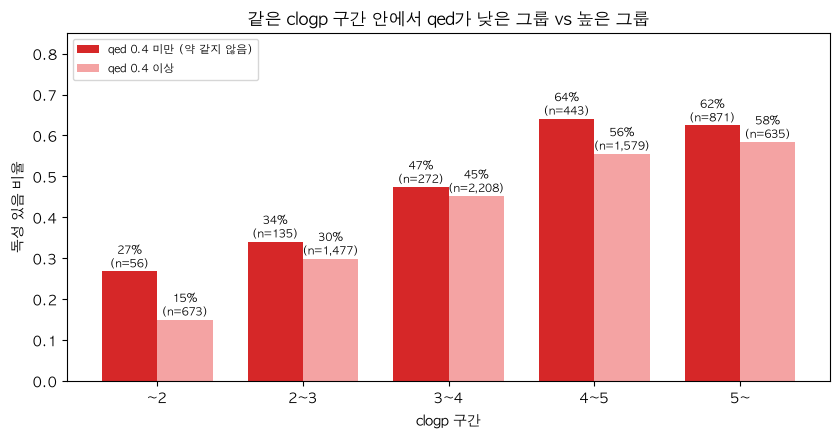

clogp>5 이면서 qed>0.7 인 화합물: 39개, 독성 82%


In [4]:
# 보충 D. 같은 clogp 구간 안에서 qed가 독성에 추가로 영향을 주는가?
tox=1-train[TARGET]
cut=pd.cut(train.clogp,[-99,2,3,4,5,99],labels=["~2","2~3","3~4","4~5","5~"])
d=train.assign(tox=tox,c=cut,q=np.where(train.qed<.4,'qed 0.4 미만','qed 0.4 이상'))
pv=d.pivot_table(index='c',columns='q',values='tox',aggfunc='mean',observed=True)
cn=d.pivot_table(index='c',columns='q',values='tox',aggfunc='count',observed=True)
fig,ax=plt.subplots(figsize=(8.5,4.5)); w=.38; xx=np.arange(5)
b1=ax.bar(xx-w/2,pv['qed 0.4 미만'],w,color=C0,label='qed 0.4 미만 (약 같지 않음)')
b2=ax.bar(xx+w/2,pv['qed 0.4 이상'],w,color='#f4a3a3',label='qed 0.4 이상')
for i in range(5):
    ax.text(i-w/2,pv['qed 0.4 미만'].iloc[i]+.01,f"{pv['qed 0.4 미만'].iloc[i]:.0%}\n(n={cn['qed 0.4 미만'].iloc[i]})",ha='center',fontsize=8)
    ax.text(i+w/2,pv['qed 0.4 이상'].iloc[i]+.01,f"{pv['qed 0.4 이상'].iloc[i]:.0%}\n(n={cn['qed 0.4 이상'].iloc[i]:,})",ha='center',fontsize=8)
ax.set_xticks(xx); ax.set_xticklabels(pv.index.astype(str)); ax.set_ylim(0,.85)
ax.set_xlabel('clogp 구간'); ax.set_ylabel('독성 있음 비율'); ax.legend(loc='upper left',fontsize=8)
ax.set_title('같은 clogp 구간 안에서 qed가 낮은 그룹 vs 높은 그룹'); plt.tight_layout(); plt.show()
print('clogp>5 이면서 qed>0.7 인 화합물: %d개, 독성 %.0f%%'%(((train.clogp>5)&(train.qed>.7)).sum(),100*tox[(train.clogp>5)&(train.qed>.7)].mean()))